In [1]:
# === Ô GHI LOG  ===
import logging, sys, datetime, warnings
from pathlib import Path
TEN_NOTEBOOK = "01_E0.1_thong_ke_mo_ta_Han"
NGUOI_CHAY   = "Han"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # thư mục gốc repo
thu_muc_log = ROOT / "logs" / "eda_log"
thu_muc_log.mkdir(parents=True, exist_ok=True)
file_log = thu_muc_log / f"{datetime.datetime.now():%Y-%m-%d_%H%M}_{TEN_NOTEBOOK}.log"
tep_log = open(file_log, "a", encoding="utf-8", buffering=1)

if hasattr(sys.stdout, "echo"):                  # chạy trong Jupyter / VS Code: nhờ kernel chép thêm ra file, không thay sys.stdout
    sys.stdout.echo = tep_log
    sys.stderr.echo = tep_log
else:                                            # chạy bằng python thường
    class GhiCaHai:
        def __init__(self, man_hinh, tep): self.man_hinh, self.tep = man_hinh, tep
        def write(self, s): self.man_hinh.write(s); self.tep.write(s); return len(s)
        def flush(self): self.man_hinh.flush(); self.tep.flush()
        def __getattr__(self, ten): return getattr(self.man_hinh, ten)
    sys.stdout = GhiCaHai(sys.__stdout__, tep_log)

logging.basicConfig(stream=sys.stdout, level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)s | %(message)s", datefmt="%Y-%m-%d %H:%M:%S")
logging.captureWarnings(True)
log = logging.getLogger(TEN_NOTEBOOK)
log.info(f"Bắt đầu chạy {TEN_NOTEBOOK} – người chạy: {NGUOI_CHAY} – file log: {file_log}")

2026-11-15 21:23:05 | INFO | Bắt đầu chạy 01_E0.1_thong_ke_mo_ta_Han – người chạy: Han – file log: /Users/caongochan/Documents/Challenge_1_House_Prices/logs/eda_log/2026-11-15_2123_01_E0.1_thong_ke_mo_ta_Han.log


# E0.1 – Dữ liệu trông thế nào? (C1 – House Prices)

| | |
|---|---|
| **Tác giả** | Cao Ngọc Hân – Nhóm 11 |
| **Ngày tạo** | 13/11/2026 |
| **Thí nghiệm** | E0.1 – Dữ liệu trông thế nào? |
| **Câu hỏi nghiên cứu** | RQ0: Những đặc trưng nào quyết định giá nhà, và cần bao nhiêu đặc trưng là đủ? |
| **Đọc vào** | `data/raw/train.csv`, `test.csv`, `data_description.txt` |
| **Ghi ra** | `figures/eda/c1_E0.1_*` (bảng tổng quan, mô tả cột, tỉ lệ thiếu, độ lệch, 3 hình), `c1_E0.1_tom_tat.txt` |

**Lịch sử sửa**

| Ngày | Người | Nội dung |
|---|---|---|
| 07–08/11/2026 | Hân | Viết trong `01_eda_Han.ipynb` (E0.1–E0.4 chung một notebook) |
| 13/11/2026 | Hân | Tách thành notebook riêng; thêm ô ghi log ra `logs/`; thêm bảng mô tả từng cột |

**Cách chạy:** chạy các notebook EDA theo thứ tự E0.1 → E0.2 → E0.3 → E0.4 (Run All). File log nằm ở `logs/eda_log/`.

In [2]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", font_scale=1.0)

SEED = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # notebook nằm ở notebooks/eda/
DATA = ROOT / "data" / "raw"
FIG = ROOT / "figures" / "eda"
FIG.mkdir(parents=True, exist_ok=True)

# W&B: USE_WANDB là công tắc chung; LOG chọn thí nghiệm nào được log ở lần chạy này.
# Thí nghiệm đã log rồi thì để False để không tạo run trùng.
# Các run W&B của E0.1–E0.4 đã log ngày 07–08/11 (xem evidence/c1_wandb_Han_10-11.png).
# Để USE_WANDB = False khi chạy lại để không tạo run trùng; bật True nếu cần log run mới.
USE_WANDB = False
LOG = {"E0.1": True}
WANDB_ENTITY = "sgu-mayhoc-nhom11"
WANDB_PROJECT = "challenge-1-house-prices"
log.info(f"ROOT: {ROOT}")

2026-11-15 21:23:07 | INFO | ROOT: /Users/caongochan/Documents/Challenge_1_House_Prices


In [3]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
TARGET = "SalePrice"
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (1460, 81) | test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## E0.1 – Dữ liệu trông thế nào?

Số mẫu, kiểu cột, tỉ lệ thiếu, phân phối biến mục tiêu.

In [4]:
X = train.drop(columns=["Id", TARGET])
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

overview = pd.DataFrame({
    "Chỉ số": ["Số mẫu train", "Số mẫu test", "Số đặc trưng", "Đặc trưng số", "Đặc trưng phân loại",
               "Cột có giá trị thiếu (train)", "Tỉ lệ ô thiếu (train)"],
    "Giá trị": [len(train), len(test), X.shape[1], len(num_cols), len(cat_cols),
                int((X.isna().sum() > 0).sum()), f"{X.isna().mean().mean():.2%}"],
})
overview.to_csv(FIG / "c1_E0.1_tong_quan.csv", index=False)
overview

,Chỉ số,Giá trị
0,Số mẫu train,1460
1,Số mẫu test,1459
2,Số đặc trưng,79
3,Đặc trưng số,36
4,Đặc trưng phân loại,43
5,Cột có giá trị thiếu (train),19
6,Tỉ lệ ô thiếu (train),6.79%


In [5]:
# Bảng mô tả từng cột: mô tả gốc lấy từ data/raw/data_description.txt (Kaggle), kiểu, số giá trị khác nhau, tỉ lệ thiếu
import re
mo_ta = {}
for line in (DATA / "data_description.txt").read_text(encoding="utf-8", errors="ignore").splitlines():
    m = re.match(r"^([A-Za-z0-9]+):\s*(.*)$", line)
    if m:
        mo_ta[m.group(1)] = m.group(2).strip()
ten_khac = {"BedroomAbvGr": "Bedroom", "KitchenAbvGr": "Kitchen"}  # tên cột khác tên trong file mô tả
bang_cot = pd.DataFrame({
    "kieu": ["số" if c in num_cols else "phân loại" for c in X.columns],
    "so_gia_tri_khac_nhau": [X[c].nunique() for c in X.columns],
    "ti_le_thieu": [X[c].isna().mean() for c in X.columns],
    "mo_ta_goc (data_description.txt)": [mo_ta.get(c, mo_ta.get(ten_khac.get(c, ""), "(không có trong file mô tả)")) for c in X.columns],
}, index=pd.Index(X.columns, name="cot"))
bang_cot.to_csv(FIG / "c1_E0.1_mo_ta_cot.csv")
log.info(f"Bảng mô tả cột: {len(bang_cot)} cột, {int((bang_cot.iloc[:, 3] == '(không có trong file mô tả)').sum())} cột không tìm thấy mô tả")
bang_cot.style.format({"ti_le_thieu": "{:.1%}"})

2026-11-15 21:23:07 | INFO | Bảng mô tả cột: 79 cột, 0 cột không tìm thấy mô tả


,kieu,so_gia_tri_khac_nhau,ti_le_thieu,mo_ta_goc (data_description.txt)
cot,,,,
MSSubClass,số,15,0.0%,Identifies the type of dwelling involved in the sale.
MSZoning,phân loại,5,0.0%,Identifies the general zoning classification of the sale.
LotFrontage,số,110,17.7%,Linear feet of street connected to property
LotArea,số,1073,0.0%,Lot size in square feet
Street,phân loại,2,0.0%,Type of road access to property
Alley,phân loại,2,93.8%,Type of alley access to property
LotShape,phân loại,4,0.0%,General shape of property
LandContour,phân loại,4,0.0%,Flatness of the property
Utilities,phân loại,2,0.0%,Type of utilities available


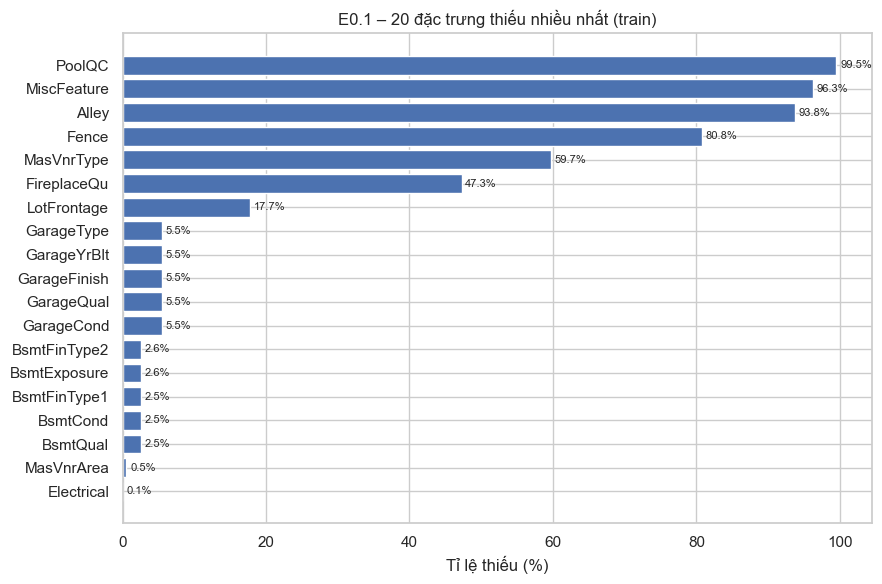

,so_thieu,ti_le,kieu
PoolQC,1453,0.995205,phân loại
MiscFeature,1406,0.963014,phân loại
Alley,1369,0.937671,phân loại
Fence,1179,0.807534,phân loại
MasVnrType,872,0.597260,phân loại
FireplaceQu,690,0.472603,phân loại
LotFrontage,259,0.177397,số
GarageType,81,0.055479,phân loại
GarageYrBlt,81,0.055479,số
GarageFinish,81,0.055479,phân loại


In [6]:
miss = (pd.DataFrame({"so_thieu": X.isna().sum(), "ti_le": X.isna().mean()})
          .query("so_thieu > 0").sort_values("ti_le", ascending=False))
miss["kieu"] = ["số" if c in num_cols else "phân loại" for c in miss.index]
miss.to_csv(FIG / "c1_E0.1_ti_le_thieu.csv")

top = miss.head(20)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index[::-1], top["ti_le"][::-1] * 100, color="#4C72B0")
ax.set_xlabel("Tỉ lệ thiếu (%)")
ax.set_title("E0.1 – 20 đặc trưng thiếu nhiều nhất (train)")
for i, v in enumerate(top["ti_le"][::-1] * 100):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "c1_E0.1_ti_le_thieu.png", dpi=150); plt.show()
miss.head(20)

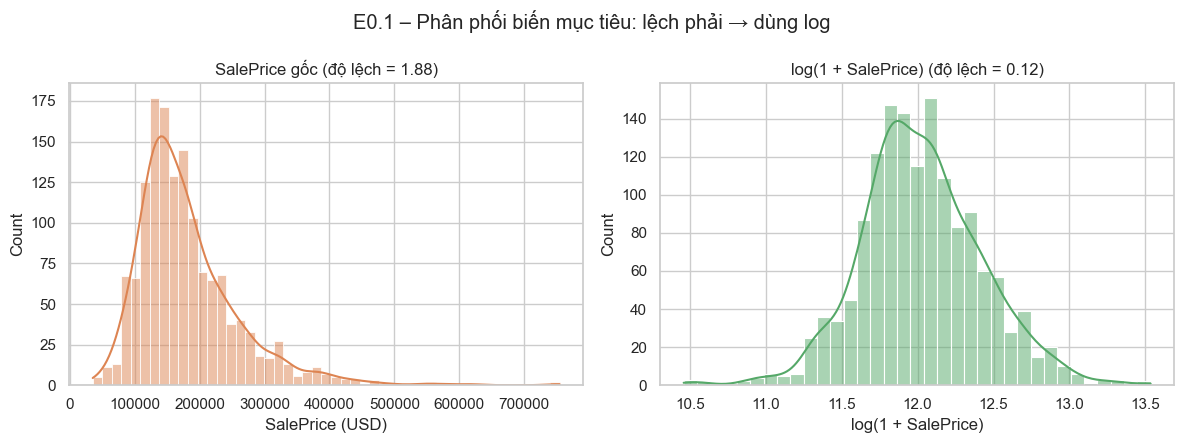

count      1460.0
mean     180921.0
std       79443.0
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64

In [7]:
y = train[TARGET]
y_log = np.log1p(y)
skew_raw, skew_log = stats.skew(y), stats.skew(y_log)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(y, kde=True, ax=axes[0], color="#DD8452")
axes[0].set_title(f"SalePrice gốc (độ lệch = {skew_raw:.2f})"); axes[0].set_xlabel("SalePrice (USD)")
sns.histplot(y_log, kde=True, ax=axes[1], color="#55A868")
axes[1].set_title(f"log(1 + SalePrice) (độ lệch = {skew_log:.2f})"); axes[1].set_xlabel("log(1 + SalePrice)")
fig.suptitle("E0.1 – Phân phối biến mục tiêu: lệch phải → dùng log")
plt.tight_layout(); plt.savefig(FIG / "c1_E0.1_phan_phoi_SalePrice.png", dpi=150); plt.show()
y.describe().round(0)

In [8]:
skew_feat = X[num_cols].apply(lambda s: stats.skew(s.dropna())).sort_values(ascending=False)
skew_tbl = skew_feat.to_frame("do_lech")
skew_tbl.to_csv(FIG / "c1_E0.1_do_lech_dac_trung_so.csv")
print("Số đặc trưng số lệch mạnh (|skew| > 1):", int((skew_feat.abs() > 1).sum()))
skew_tbl.head(10).round(2)

Số đặc trưng số lệch mạnh (|skew| > 1): 19


,do_lech
MiscVal,24.45
PoolArea,14.81
LotArea,12.20
3SsnPorch,10.29
LowQualFinSF,9.00
KitchenAbvGr,4.48
BsmtFinSF2,4.25
ScreenPorch,4.12
BsmtHalfBath,4.10
EnclosedPorch,3.09


2026-11-15 21:23:07 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-15 21:23:07 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


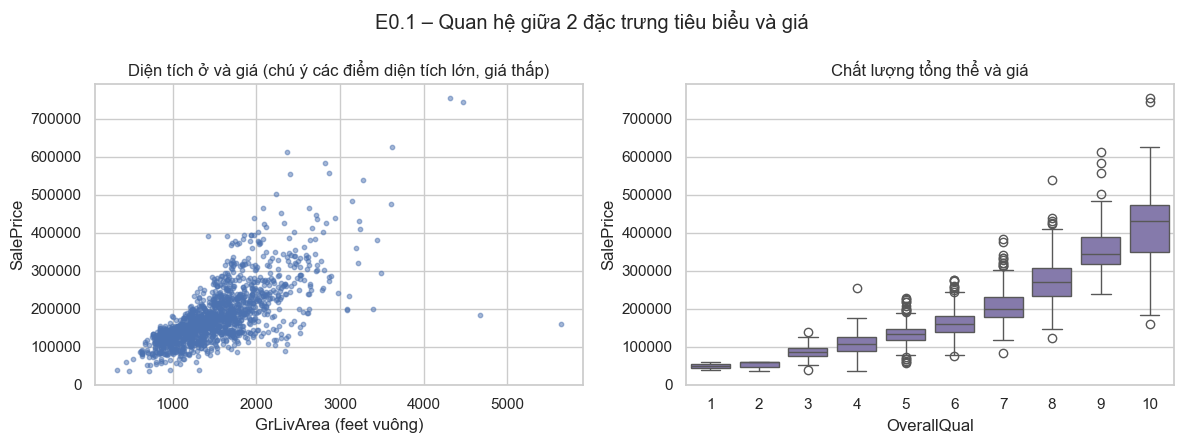

In [9]:
# Hai đặc trưng thường liên quan giá nhất: diện tích ở và chất lượng tổng thể
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(train["GrLivArea"], y, s=10, alpha=0.5)
axes[0].set_xlabel("GrLivArea (feet vuông)"); axes[0].set_ylabel("SalePrice")
axes[0].set_title("Diện tích ở và giá (chú ý các điểm diện tích lớn, giá thấp)")
sns.boxplot(x=train["OverallQual"], y=y, ax=axes[1], color="#8172B3")
axes[1].set_title("Chất lượng tổng thể và giá")
fig.suptitle("E0.1 – Quan hệ giữa 2 đặc trưng tiêu biểu và giá")
plt.tight_layout(); plt.savefig(FIG / "c1_E0.1_GrLivArea_OverallQual.png", dpi=150); plt.show()

## Tóm tắt E0.1

In [10]:
summary = f"""E0.1 (C1): {len(train)} mẫu train, {len(test)} mẫu test, {X.shape[1]} đặc trưng ({len(num_cols)} số, {len(cat_cols)} phân loại).
  {len(miss)} cột có giá trị thiếu; thiếu nhiều nhất: {', '.join(f'{c} ({p:.0%})' for c, p in miss['ti_le'].head(4).items())}.
  SalePrice lệch phải (skew = {skew_raw:.2f}); sau log còn {skew_log:.2f} → dùng log(1+SalePrice) làm mục tiêu.
  {int((skew_feat.abs() > 1).sum())} đặc trưng số lệch mạnh (|skew| > 1)."""
log.info("Tóm tắt " + "E0.1" + ":\n" + summary)
(FIG / "c1_E0.1_tom_tat.txt").write_text(summary, encoding="utf-8")

2026-11-15 21:23:08 | INFO | Tóm tắt E0.1:
E0.1 (C1): 1460 mẫu train, 1459 mẫu test, 79 đặc trưng (36 số, 43 phân loại).
  19 cột có giá trị thiếu; thiếu nhiều nhất: PoolQC (100%), MiscFeature (96%), Alley (94%), Fence (81%).
  SalePrice lệch phải (skew = 1.88); sau log còn 0.12 → dùng log(1+SalePrice) làm mục tiêu.
  19 đặc trưng số lệch mạnh (|skew| > 1).


316

## Log lên W&B (minh chứng)

In [11]:
if USE_WANDB:
    import wandb
    def log_run(exp, name, metrics, tables, images, config=None):
        if not LOG.get(exp):
            print(f"Bỏ qua {exp} (LOG = False)"); return
        run = wandb.init(entity=WANDB_ENTITY, project=WANDB_PROJECT, name=name,
                         tags=[exp, "Han", "EDA"], config={"seed": SEED, **(config or {})})
        run.log({**metrics,
                 **{k: wandb.Table(dataframe=v) for k, v in tables.items()},
                 **{f.removesuffix(".png"): wandb.Image(str(FIG / f)) for f in images}})
        run.finish()

    log_run("E0.1", "c1-E0.1-Han-thong-ke-mo-ta",
            {"n_train": len(train), "n_test": len(test), "n_features": X.shape[1],
             "n_numeric": len(num_cols), "n_categorical": len(cat_cols), "n_cols_missing": len(miss),
             "skew_saleprice": skew_raw, "skew_log_saleprice": skew_log},
            {"bang_ti_le_thieu": miss.reset_index(names="dac_trung")},
            ["c1_E0.1_ti_le_thieu.png", "c1_E0.1_phan_phoi_SalePrice.png", "c1_E0.1_GrLivArea_OverallQual.png"])


## Nhật ký

- 07/11/2026 – Viết thống kê mô tả (E0.1) lần đầu trong notebook `01_eda_TV1.ipynb`. Commit `68a3cbe`.
- 07/11/2026 – Đổi tên notebook `01_eda_TV1.ipynb` thành `01_eda_Han.ipynb`. Commit `7496f72`.
- 13/11/2026 – Tách E0.1 ra thành notebook riêng `01_E0.1_thong_ke_mo_ta_Han.ipynb`, thêm ô ghi log và bảng mô tả 79 cột (`c1_E0.1_mo_ta_cot.csv`). Chạy lại, số khớp bản 08/11. Commit `e106d69`.